# Projet 2

In [31]:
import os, re
from glob import glob as ls
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import seaborn as sns; sns.set()
import qgrid
from PIL import Image
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings("ignore")
from sys import path
from intro_science_donnees import *
from intro_science_donnees import data
from utilities import *


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
dataset_dir = 'data/512x512/'
images = load_images(dataset_dir, "*.jpg")

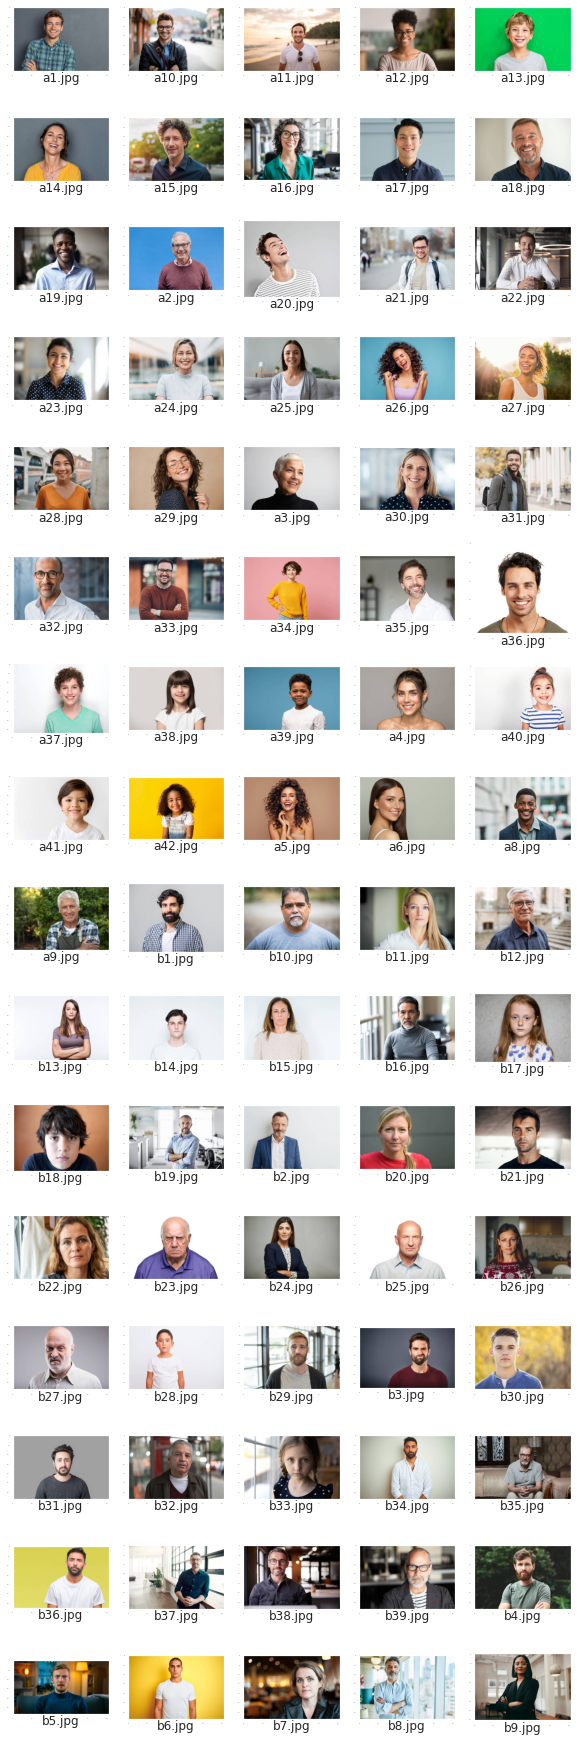

In [33]:
image_grid(images, titles=images.index)

In [34]:
images

a1.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
a10.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a11.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a12.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a13.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
                                 ...                        
b5.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b6.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b7.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b8.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b9.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
Length: 80, dtype: object

In [35]:
type(images)

pandas.core.series.Series

In [36]:
images.index

Index(['a1.jpg', 'a10.jpg', 'a11.jpg', 'a12.jpg', 'a13.jpg', 'a14.jpg',
       'a15.jpg', 'a16.jpg', 'a17.jpg', 'a18.jpg', 'a19.jpg', 'a2.jpg',
       'a20.jpg', 'a21.jpg', 'a22.jpg', 'a23.jpg', 'a24.jpg', 'a25.jpg',
       'a26.jpg', 'a27.jpg', 'a28.jpg', 'a29.jpg', 'a3.jpg', 'a30.jpg',
       'a31.jpg', 'a32.jpg', 'a33.jpg', 'a34.jpg', 'a35.jpg', 'a36.jpg',
       'a37.jpg', 'a38.jpg', 'a39.jpg', 'a4.jpg', 'a40.jpg', 'a41.jpg',
       'a42.jpg', 'a5.jpg', 'a6.jpg', 'a8.jpg', 'a9.jpg', 'b1.jpg', 'b10.jpg',
       'b11.jpg', 'b12.jpg', 'b13.jpg', 'b14.jpg', 'b15.jpg', 'b16.jpg',
       'b17.jpg', 'b18.jpg', 'b19.jpg', 'b2.jpg', 'b20.jpg', 'b21.jpg',
       'b22.jpg', 'b23.jpg', 'b24.jpg', 'b25.jpg', 'b26.jpg', 'b27.jpg',
       'b28.jpg', 'b29.jpg', 'b3.jpg', 'b30.jpg', 'b31.jpg', 'b32.jpg',
       'b33.jpg', 'b34.jpg', 'b35.jpg', 'b36.jpg', 'b37.jpg', 'b38.jpg',
       'b39.jpg', 'b4.jpg', 'b5.jpg', 'b6.jpg', 'b7.jpg', 'b8.jpg', 'b9.jpg'],
      dtype='object')

In [37]:
d = {"Class": [1 if s[0] == 'a' else -1 for s in images.index]
}

In [38]:
data = pd.DataFrame(data=d, index=images.index)
data

,Class
a1.jpg,1
a10.jpg,1
a11.jpg,1
a12.jpg,1
a13.jpg,1
...,...
b5.jpg,-1
b6.jpg,-1
b7.jpg,-1
b8.jpg,-1


In [76]:
def calc_seuil(img : Image.Image) -> int:
    n = np.array(img)
    G = np.min(n[:, :, 0:3], axis=2)
    return((np.mean(G) + np.std(G))/2)

def invert(n : np.ndarray, force : bool = False) -> np.ndarray:
    G = n.mean()
    return np.invert(n) if force or G > 0.5 else n


img = images[6]
image_grid([invert(foreground_filter(img, calc_seuil(img))), invert(foreground_filter(img, calc_seuil(img)))])
print(np.argwhere(invert(foreground_filter(img, calc_seuil(img)))))

[[  0   0]
 [  0   1]
 [  0   2]
 ...
 [339 121]
 [339 122]
 [339 123]]


In [40]:
img_foreground = np.array([invert(foreground_filter(img, calc_seuil(img))) for img in images])

In [41]:
img_foreground

array([array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
             

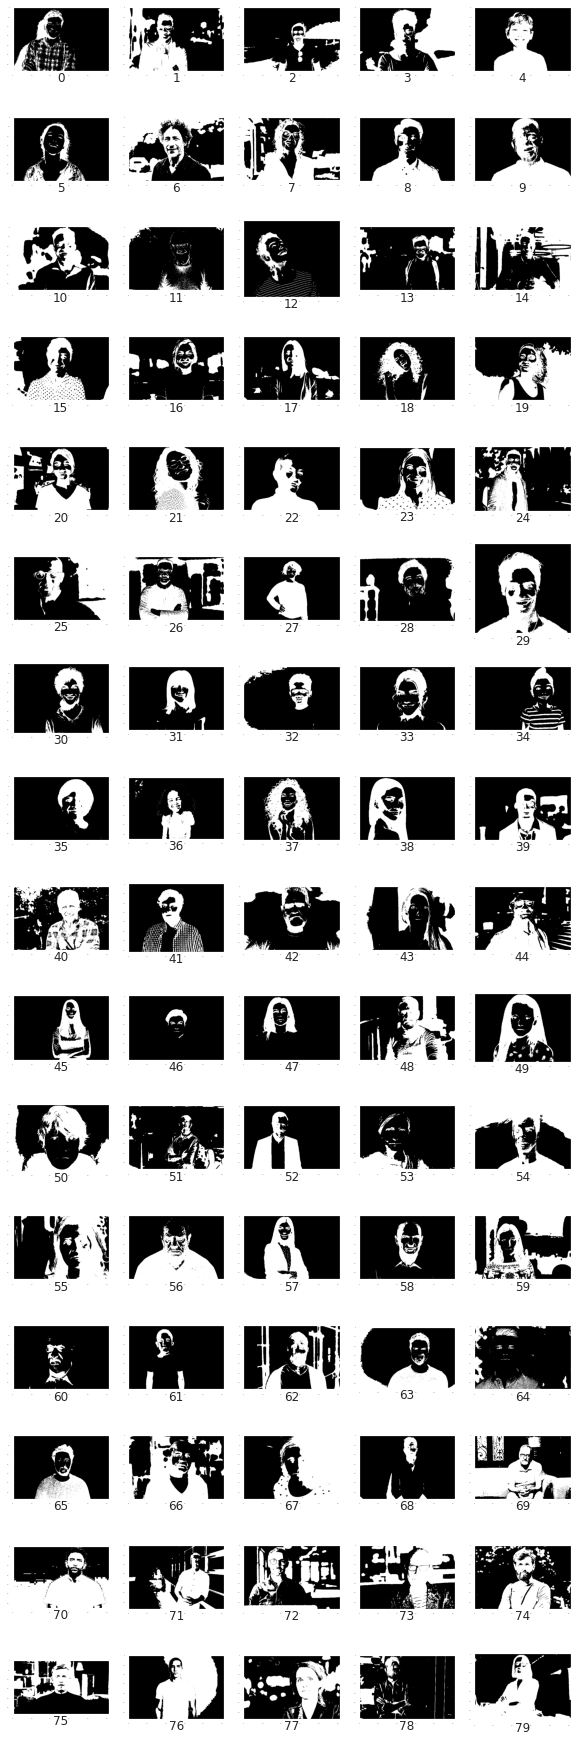

In [42]:
image_grid(img_foreground)

In [43]:
img_barycentre = np.array([place_barycentre(img) for img in img_foreground])

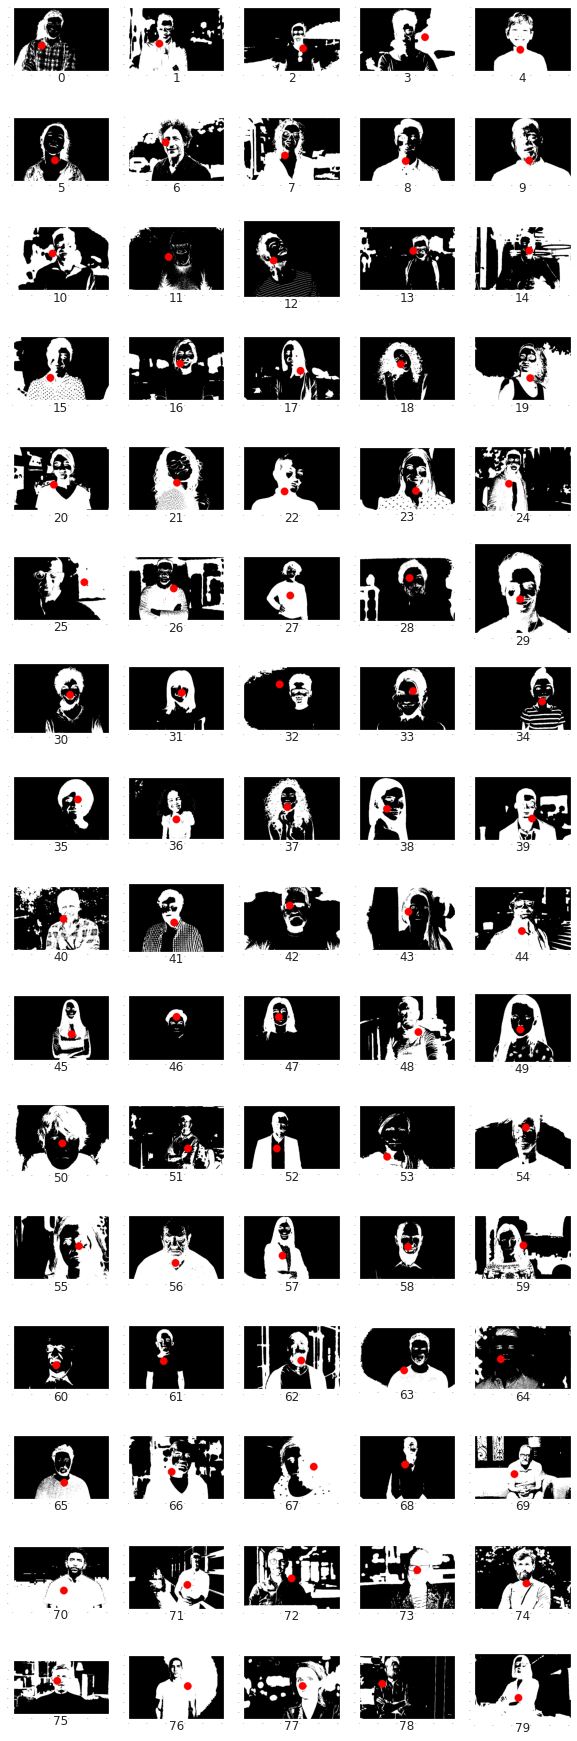

In [44]:
image_grid(img_barycentre)

In [45]:
img_barycentre

array([<PIL.Image.Image image mode=RGB size=512x340 at 0x7FBFC6540CA0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7FAB3A0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7FAB970>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7EC3D30>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7EC39D0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7EC3460>,
       <PIL.Image.Image image mode=RGB size=512x340 at 0x7FBFC7EC3670>,
       <PIL.Image.Image image mode=RGB size=512x337 at 0x7FBFC7EC3E20>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC64CE790>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC7F438E0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC6423730>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC67A1C10>,
       <PIL.Image.Image image mode=RGB size=512x410 at 0x7FBFC83F2F40>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7FBFC64

In [46]:
img_foreground[0].shape

(340, 512)

In [47]:
images_cropped = pd.Series([crop_around_barycentre(img_foreground[i], images[i]) for i in range(len(images))])
images_cropped.index = images.index

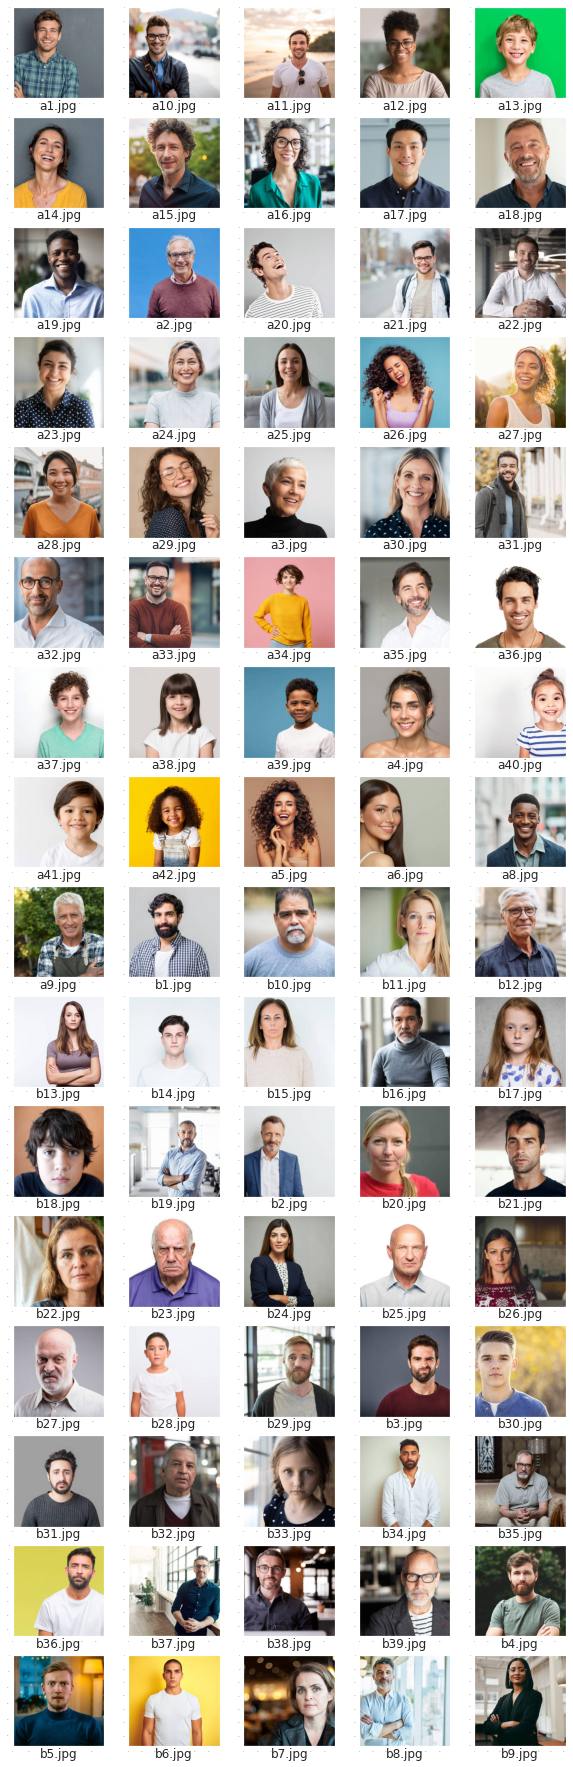

In [48]:
image_grid(images_cropped, titles=images_cropped.index)

In [98]:
images_resize = pd.Series([img.resize((64, 64)) for img in images_cropped])
images_resize.index = images.index

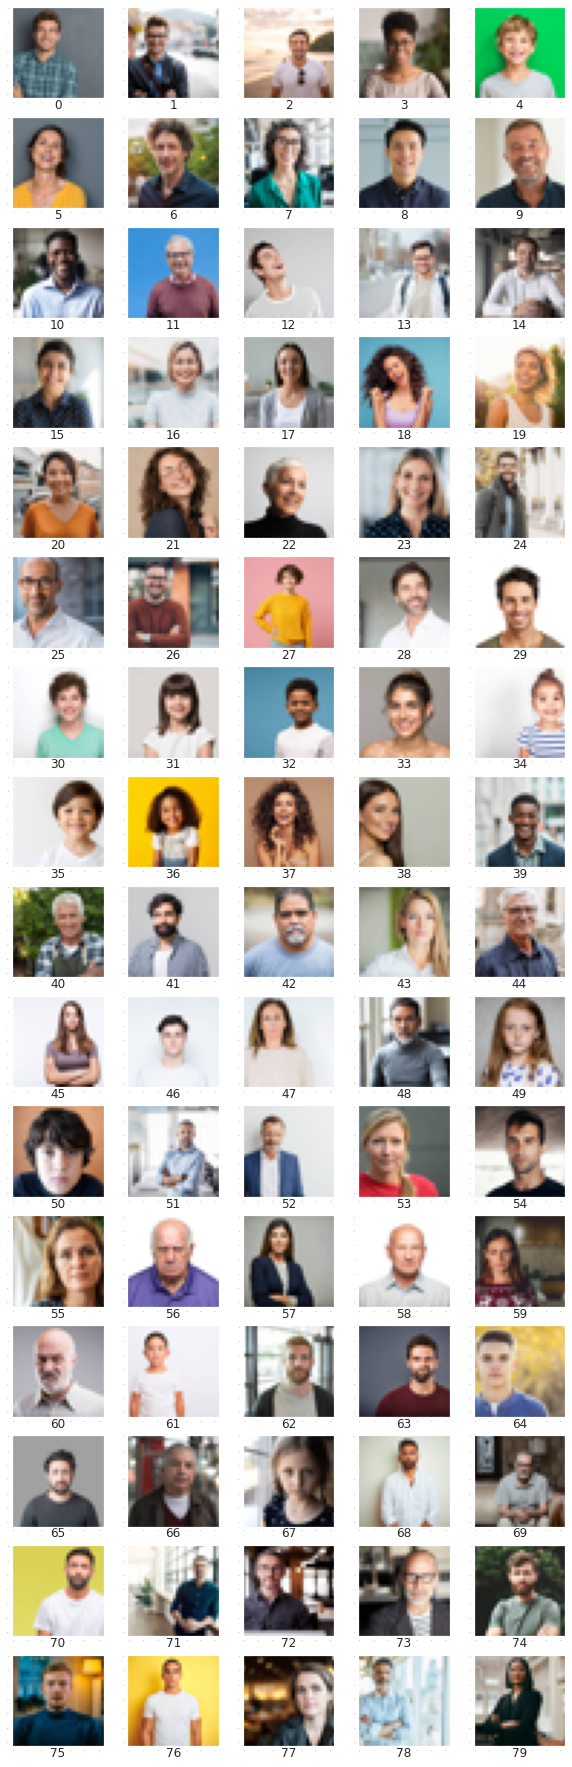

In [86]:
image_grid(images_resize)

In [51]:
print(np.array([images_cropped]))

[[<PIL.Image.Image image mode=RGB size=340x340 at 0x7FBFC5161AC0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC4911E20>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC7EC33A0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC7EC36A0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC7EC3700>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC7EC3F40>
  <PIL.Image.Image image mode=RGB size=340x340 at 0x7FBFC7EC3CD0>
  <PIL.Image.Image image mode=RGB size=337x337 at 0x7FBFC7EC3E80>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC7EC3AF0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC643D430>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC643D1F0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC643D4C0>
  <PIL.Image.Image image mode=RGB size=410x410 at 0x7FBFC643D220>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC643D2B0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7FBFC643DC70>
  <PIL.Ima

In [52]:
print(np.array(images_resize))

[<PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC4746DF0>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2FA3040>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFD5D62D30>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2C23D00>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2C23580>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2C23220>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2C23DC0>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2C23400>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2FC4730>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC2D84070>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC35419A0>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC35418B0>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC3541A60>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC3541A00>
 <PIL.Image.Image image mode=RGB size=256x256 at 0x7FBFC3541A90>
 <PIL.Image.Image image m

In [53]:
#for i,img in enumerate(images_resize):
#    img.save("data/resize/"+images_resize.index[i])


In [54]:
foreground = pd.Series([invert(foreground_filter(img, 60)) for img in images_resize])

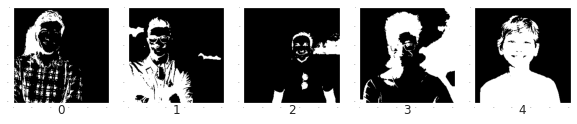

In [55]:
image_grid(foreground.head())

In [59]:
def color_correlation_filter(
    img: Union[Image.Image, np.ndarray], color: np.ndarray
) -> np.ndarray:
    """Return a grey-level image measuring the correlation of the pixels
    with the given color."""
    N = np.array(img, dtype='float64')
    r = np.array([[abs(np.corrcoef(linPix[i][0:3], color)[0, 1]) for i in range(len(linPix))] for linPix in N])
    return r

In [114]:
def color_fist_line(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[:, 0, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_fist_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[0, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_last_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[-1, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

In [115]:
background = np.array([(color_correlation_filter(img, color_fist_line(img)) + color_correlation_filter(img, color_fist_colonne(img)) + color_correlation_filter(img, color_last_colonne(img))) for img in images_resize])

In [195]:
background2 = np.array([(color_correlation_filter(img, (0,0,255)) + color_correlation_filter(img, (0,255,0))) for img in images_resize])

In [ ]:
moyennes = [background[i].mean for i in range(len(background))]

In [338]:
contour = np.array([contours(img) for img in images_resize])

In [372]:
def superieur_couleur(M : np.ndarray) -> np.ndarray:
    N = [[False for j in range(len(M))] for i in range(len(M))]


    for x, l in enumerate(M):
        for y, l2 in enumerate(l):
            r, g, b = l2 > 40
            N[x][y] = r and g and b
    return N

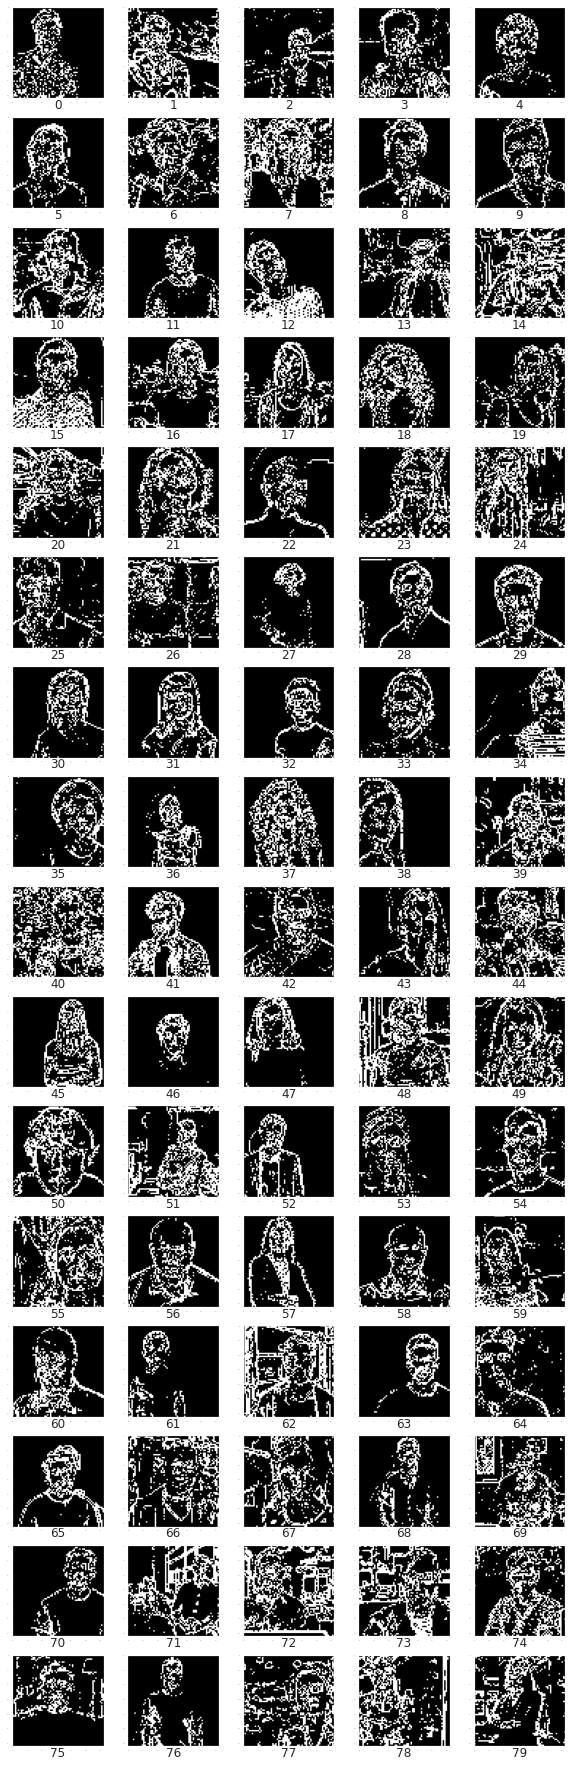

In [373]:
image_grid([superieur_couleur(img) for img in contour])